**Part 1: Loading the dataset:**

In [3]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
%matplotlib inline

In [4]:
#loading the BANKING77 dataset
url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/"

#dataset comes already split into training and test set
train = pd.read_csv(url + "train.csv")
test = pd.read_csv(url + "test.csv")


Check the data:

In [5]:
#check the sizes
print("Dataset sizes:")
print("training set:", train.shape)
print("test set:", test.shape)
print("")

#check number of classes in each set
print("# of classes:")
print("classes in training set:", train["category"].nunique())
print("classes in test set:", test["category"].nunique())
print("")

#check for missing values
print("# of missing values:")
print("missing values in training set:", train.isna().sum().sum())
print("missing values in test set:", test.isna().sum().sum())
print("")

#count how many examples each class has
print("Spread of examples across classes:")
counts = train["category"].value_counts()
print("fewest examples per intent:", counts.min())
print("most examples per intent:", counts.max())

Dataset sizes:
training set: (10003, 2)
test set: (3080, 2)

# of classes:
classes in training set: 77
classes in test set: 77

# of missing values:
missing values in training set: 0
missing values in test set: 0

Spread of examples across classes:
fewest examples per intent: 35
most examples per intent: 187


Create validation set:

In [6]:
#features are the question text and labels are the intents
X_train_full = train["text"]
y_train_full = train["category"]
X_test = test["text"]
y_test = test["category"]

#split the training set into 80% train and 20% validation
#stratify keeps the same proportion of each classes in both sets and random_state keeps the split the same every run
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=1)

#check the sizes
print("check dataset sizes:")
print("training set:", X_train.shape)
print("validation set:", X_val.shape)
print("test set:", X_test.shape)

check dataset sizes:
training set: (8002,)
validation set: (2001,)
test set: (3080,)


**Part 2: Preprocessing**

In [7]:
import string

#remove any uppercase, punctuation, and white space
def clean(text):
  text = text.lower()
  for char in string.punctuation:
    text = text.replace(char, "")
  text = " ".join(text.split())
  return text

#clean every question in the training set
X_train_clean = []
for question in X_train:
  X_train_clean.append(clean(question))

#clean every question in the validation set
X_val_clean = []
for question in X_val:
  X_val_clean.append(clean(question))

#clean every question in the test set
X_test_clean = []
for question in X_test:
  X_test_clean.append(clean(question))

Create TF-IDF features

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

#create the TF-IDF vectorizer (one feature per word)
tfidf = TfidfVectorizer()

#learn the vocabulary and IDF weights from the training set ONLY to prevent leakage and column mismatch
tfidf.fit(X_train_clean)

#transform all three sets into TF-IDF features using what was learned from training fit
X_train_tfidf = tfidf.transform(X_train_clean)
X_val_tfidf = tfidf.transform(X_val_clean)
X_test_tfidf = tfidf.transform(X_test_clean)

#number of TF-IDF features (words in the vocabulary)
print("number of TF-IDF features:", X_train_tfidf.shape[1])


number of TF-IDF features: 2181


**Part 3: Training**

In [9]:
#imports
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import f1_score

Baseline model:

In [10]:
#majority class baseline --> always predicts the most common intent in the training set
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_tfidf, y_train)


DummyClassifier(strategy='most_frequent')

Logistic Regression - find best lambda

In [11]:
#regularization strengths
lambdas  = [100, 10, 1, 0.1, 0.01, 0.001]

#keep track of the best lambda and its score
best_lr_score = 0
best_lr_lambda = None

for l in lambdas:
  #sklearn uses C = 1/lambda
  lr_model = LogisticRegression(C=1/l, max_iter=1000)
  lr_model.fit(X_train_tfidf, y_train)
  #use validation set to pick the best c
  lr_pred = lr_model.predict(X_val_tfidf)
  score = f1_score(y_val, lr_pred, average="macro")
  print("lambda =", l, " validation macro F1 =", score)

  #save lambda if its higher than the best score so far
  if score > best_lr_score:
    best_lr_score = score
    best_lr_lambda = l

print("best lambda =", best_lr_lambda, " with validation macro F1 =", best_lr_score)


lambda = 100  validation macro F1 = 0.13020036450465686
lambda = 10  validation macro F1 = 0.6719268506411741
lambda = 1  validation macro F1 = 0.8515917147915861
lambda = 0.1  validation macro F1 = 0.8818145883953975
lambda = 0.01  validation macro F1 = 0.8821631182268548
lambda = 0.001  validation macro F1 = 0.878053449636169
best lambda = 0.01  with validation macro F1 = 0.8821631182268548


Linear SVM - find best lambda

In [12]:
#keep track of the best lambda and its score
best_svm_score = 0
best_svm_lambda = None

for l in lambdas:
  #sklearn uses squared hinge loss --> we convert this to standard hinge loss
  svm_model = LinearSVC(C=1/l, loss="hinge", max_iter=100000)
  svm_model.fit(X_train_tfidf, y_train)
  svm_pred = svm_model.predict(X_val_tfidf)
  score = f1_score(y_val, svm_pred, average="macro")
  print("lambda =", l, " validation macro F1 =", score)

  #save lambda if its higher than the best score so far
  if score > best_svm_score:
    best_svm_score = score
    best_svm_lambda = l

print("best lambda =", best_svm_lambda, " with validation macro F1 =", best_svm_score)

lambda = 100  validation macro F1 = 0.7866361023346271
lambda = 10  validation macro F1 = 0.8068497806419441
lambda = 1  validation macro F1 = 0.8573933670113626
lambda = 0.1  validation macro F1 = 0.8704005512047062
lambda = 0.01  validation macro F1 = 0.8378456812319844
lambda = 0.001  validation macro F1 = 0.825930268470517
best lambda = 0.1  with validation macro F1 = 0.8704005512047062


Radial Basis Function SVM - find best gamma and lambda

In [13]:
from sklearn.svm import SVC

#tune lambda with gamma fixed at sklearn's default ("scale")
rbf_lambdas = [10, 1, 0.1, 0.01, 0.001]

#keep track of the best lambda and its score
best_rbf_score = 0
best_rbf_lambda = None

for l in rbf_lambdas:
  rbf_model = SVC(kernel="rbf", C=1/l, gamma="scale")
  rbf_model.fit(X_train_tfidf, y_train)
  rbf_pred = rbf_model.predict(X_val_tfidf)
  score = f1_score(y_val, rbf_pred, average="macro")
  print("lambda =", l, " validation macro F1 =", score)

  #save lambda if its higher than the best score so far
  if score > best_rbf_score:
    best_rbf_score = score
    best_rbf_lambda = l

print("best lambda =", best_rbf_lambda, " with validation macro F1 =", best_rbf_score)

lambda = 10  validation macro F1 = 0.40122918876047725
lambda = 1  validation macro F1 = 0.8838980115027005
lambda = 0.1  validation macro F1 = 0.8893453436742218
lambda = 0.01  validation macro F1 = 0.8893453436742218
lambda = 0.001  validation macro F1 = 0.8893453436742218
best lambda = 0.1  with validation macro F1 = 0.8893453436742218


In [14]:
#tune gamma with lambda fixed at its best value
gammas = [0.1, 0.5, 1, 2]

#keep track of the best gamma and its score
best_rbf_score = 0
best_rbf_gamma = None

for g in gammas:
  rbf_model = SVC(kernel="rbf", C=1/best_rbf_lambda, gamma=g)
  rbf_model.fit(X_train_tfidf, y_train)
  rbf_pred = rbf_model.predict(X_val_tfidf)
  score = f1_score(y_val, rbf_pred, average="macro")
  print("gamma =", g, " validation macro F1 =", score)

  #save gamma if its higher than the best score so far
  if score > best_rbf_score:
    best_rbf_score = score
    best_rbf_gamma = g

print("best gamma =", best_rbf_gamma, " with validation macro F1 =", best_rbf_score)

gamma = 0.1  validation macro F1 = 0.8857716922822417
gamma = 0.5  validation macro F1 = 0.8924065140194858
gamma = 1  validation macro F1 = 0.8893453436742218
gamma = 2  validation macro F1 = 0.8667217922815493
best gamma = 0.5  with validation macro F1 = 0.8924065140194858


Multinomial Naive Bayes - find best alpha

In [15]:
#alpha smoothing parameter values
alpha_values = [0.001, 0.01, 0.1, 1]

#keep track of the best alpha and its score
best_nb_score = 0
best_nb_alpha = None

for a in alpha_values:
  nb_model = MultinomialNB(alpha=a)
  nb_model.fit(X_train_tfidf, y_train)
  nb_pred = nb_model.predict(X_val_tfidf)
  score = f1_score(y_val, nb_pred, average="macro")
  print("alpha =", a, " validation macro F1 =", score)

  #save alpha if its higher than the best score so far
  if score > best_nb_score:
    best_nb_score = score
    best_nb_alpha = a

print("best alpha =", best_nb_alpha, " with validation macro F1 =", best_nb_score)

alpha = 0.001  validation macro F1 = 0.8158876796569806
alpha = 0.01  validation macro F1 = 0.8308869365397229
alpha = 0.1  validation macro F1 = 0.8402982439483108
alpha = 1  validation macro F1 = 0.7695141797936093
best alpha = 0.1  with validation macro F1 = 0.8402982439483108


Train final models with best hyperparameters

In [16]:
#train the final version of each model using the best hyperparameters
lr_model = LogisticRegression(C=1/best_lr_lambda, max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

svm_model = LinearSVC(C=1/best_svm_lambda, loss="hinge", max_iter=100000)
svm_model.fit(X_train_tfidf, y_train)

nb_model = MultinomialNB(alpha=best_nb_alpha)
nb_model.fit(X_train_tfidf, y_train)

rbf_model = SVC(kernel="rbf", C=1/best_rbf_lambda, gamma=best_rbf_gamma)
rbf_model.fit(X_train_tfidf, y_train)

SVC(C=10.0, gamma=0.5)

**Part 4: Evaluating the Model**

In [17]:
#imports
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

Predictions on test set

In [18]:
models = {"Baseline": baseline, "Logistic Regression": lr_model, "Linear SVM": svm_model, "Naive Bayes": nb_model, "RBF SVM": rbf_model}
#predict the intent of every test question with each model
test_preds = {}
for name in models:
  test_preds[name] = models[name].predict(X_test_tfidf)

Calculate evaluation metrics

In [19]:
#calculate accuracy, precision, recall, and F1 for each model
results = []
for name in models:
  pred = test_preds[name]
  results.append({
    "model": name,
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred, average="macro", zero_division=0),
    "recall": recall_score(y_test, pred, average="macro", zero_division=0),
    "F1": f1_score(y_test, pred, average="macro", zero_division=0)
  })

#print results as a table
results_table = pd.DataFrame(results)
print(results_table.round(3))


                 model  accuracy  precision  recall     F1
0             Baseline     0.013      0.000   0.013  0.000
1  Logistic Regression     0.879      0.884   0.879  0.879
2           Linear SVM     0.874      0.877   0.874  0.874
3          Naive Bayes     0.835      0.848   0.835  0.832
4              RBF SVM     0.895      0.901   0.895  0.895


Find best model

In [20]:
#remove the baseline so we only compare the four real models
model_rows = results_table[results_table["model"] != "Baseline"]

#find the best model for each metric
winners = []
for metric in ["accuracy", "precision", "recall", "F1"]:
  winners.append(model_rows.loc[model_rows[metric].idxmax(), "model"])

#if one model wins every metric use it otherwise fall back to macro F1
if len(set(winners)) == 1:
  best_model_name = winners[0]
else:
  best_model_name = model_rows.loc[model_rows["F1"].idxmax(), "model"]

print("best model:", best_model_name)


best model: RBF SVM


Bar chart of macro F1 scores

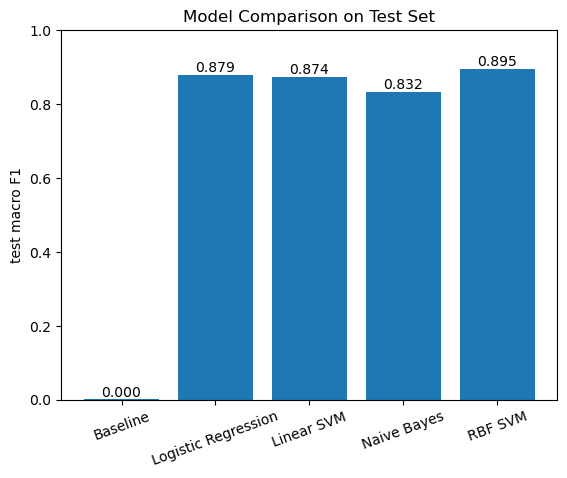

In [21]:
#bar chart comparing macro F1 for each model
bars = plt.bar(results_table["model"], results_table["F1"])

#write each bar's value on top of it (rounded to 3 decimals)
plt.bar_label(bars, fmt="%.3f")

plt.ylabel("test macro F1")
plt.title("Model Comparison on Test Set")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

**Part 5: Clustering Intents**

Make each class a normalized vector of its features

In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

#list of the 77 classes
classes = np.unique(y_train)
y_train_array = np.array(y_train)

#each class vector is the average TF-IDF vector of its training questions
class_vectors = []
for c in classes:
  rows = X_train_tfidf[y_train_array == c]
  class_vectors.append(np.asarray(rows.mean(axis=0)).flatten())
class_vectors = np.array(class_vectors)

#scale each vector to length 1 (want to compare relative patterns not word counts)
class_vectors = normalize(class_vectors)
print("class vectors:", class_vectors.shape)

class vectors: (77, 2181)


K-means - find best K

In [23]:
K_values = [2, 5, 8, 10, 12, 15, 17, 20, 25]

#keep track of the best K and its score
best_score = -1
best_K = None

for K in K_values:
  kmeans = KMeans(n_clusters=K, n_init=10, random_state=1)
  labels = kmeans.fit_predict(class_vectors)
  score = silhouette_score(class_vectors, labels, metric="cosine")
  print("K =", K, " silhouette score =", score)

  #save this K if it beats the best score so far
  if score > best_score:
    best_score = score
    best_K = K

print("best K =", best_K)

K = 2  silhouette score = 0.08315607128690933
K = 5  silhouette score = 0.1164669293660174
K = 8  silhouette score = 0.1374929009706189
K = 10  silhouette score = 0.13236092806892977
K = 12  silhouette score = 0.18298787549841322
K = 15  silhouette score = 0.19584001858598346
K = 17  silhouette score = 0.1807271313219866
K = 20  silhouette score = 0.18423319549405517
K = 25  silhouette score = 0.19267999754789053
best K = 15


K-means clusters

In [24]:
#run k-means with the best K
kmeans = KMeans(n_clusters=best_K, n_init=10, random_state=1)
cluster_labels = kmeans.fit_predict(class_vectors)

#dictionary of class (key) to cluster number
class_cluster = {}
for i in range(len(classes)):
    class_cluster[classes[i]] = cluster_labels[i]

#print the classes in each cluster
for k in np.unique(cluster_labels):
    print("Cluster", k, ":", list(classes[cluster_labels == k]))

Cluster 0 : ['age_limit', 'cancel_transfer', 'edit_personal_details', 'receiving_money', 'terminate_account', 'top_up_by_bank_transfer_charge', 'transfer_into_account', 'verify_source_of_funds']
Cluster 1 : ['compromised_card', 'lost_or_stolen_card', 'lost_or_stolen_phone', 'passcode_forgotten']
Cluster 2 : ['apple_pay_or_google_pay', 'automatic_top_up', 'contactless_not_working', 'pending_top_up', 'top_up_by_cash_or_cheque', 'top_up_failed', 'top_up_limits', 'top_up_reverted', 'topping_up_by_card', 'verify_top_up']
Cluster 3 : ['country_support']
Cluster 4 : ['cash_withdrawal_not_recognised', 'declined_cash_withdrawal', 'pending_cash_withdrawal', 'wrong_amount_of_cash_received']
Cluster 5 : ['change_pin', 'get_physical_card', 'pin_blocked']
Cluster 6 : ['card_payment_fee_charged', 'cash_withdrawal_charge', 'extra_charge_on_statement', 'top_up_by_card_charge', 'transaction_charged_twice', 'transfer_fee_charged']
Cluster 7 : ['card_payment_wrong_exchange_rate', 'exchange_rate', 'wrong_e

DBSCAN - find best ε

In [25]:
from sklearn.cluster import DBSCAN

min_pts = 3

#try different epsilon values and see how many clusters and noise points each gives
eps_values = [0.3, 0.35, 0.4, 0.42, 0.45, 0.5, 0.55]

for e in eps_values:
    #run DBSCAN (labels noise as -1)
    db_labels = DBSCAN(eps=e, min_samples=min_pts, metric="cosine").fit_predict(class_vectors)

    #count the size of each cluster and the number of noise intents
    cluster_sizes = {}
    noise = 0
    for label in db_labels:
        if label == -1:
            noise += 1
        else:
            cluster_sizes[label] = cluster_sizes.get(label, 0) + 1

    #number of clusters and size of the largest one
    clusters = len(cluster_sizes)
    largest = max(cluster_sizes.values())

    print("eps =", e, " clusters =", clusters, " noise intents =", noise, " largest cluster =", largest)

eps = 0.3  clusters = 4  noise intents = 64  largest cluster = 4
eps = 0.35  clusters = 5  noise intents = 61  largest cluster = 4
eps = 0.4  clusters = 8  noise intents = 47  largest cluster = 5
eps = 0.42  clusters = 8  noise intents = 38  largest cluster = 11
eps = 0.45  clusters = 5  noise intents = 31  largest cluster = 33
eps = 0.5  clusters = 4  noise intents = 19  largest cluster = 49
eps = 0.55  clusters = 3  noise intents = 9  largest cluster = 61


DBSCAN clusters

In [26]:
#largest eps before clusters start merging into one large group
best_e = 0.4

#using cosine similarity as the distance function
db_labels = DBSCAN(eps=best_e, min_samples=min_pts, metric="cosine").fit_predict(class_vectors)

#dictionary of class (key) to cluster #
db_cluster = {}
for i in range(len(classes)):
  db_cluster[classes[i]] = db_labels[i]

#print each cluster and the noise intents
for k in np.unique(db_labels):
  if k != -1:
    print("Cluster", k, ":", list(classes[db_labels == k]))
print("")
print("Noise:", list(classes[db_labels == -1]))

Cluster 0 : ['balance_not_updated_after_bank_transfer', 'transfer_not_received_by_recipient', 'transfer_timing']
Cluster 1 : ['card_payment_fee_charged', 'cash_withdrawal_charge', 'extra_charge_on_statement', 'transfer_fee_charged']
Cluster 2 : ['card_payment_wrong_exchange_rate', 'exchange_rate', 'wrong_exchange_rate_for_cash_withdrawal']
Cluster 3 : ['change_pin', 'get_physical_card', 'pin_blocked']
Cluster 4 : ['beneficiary_not_allowed', 'declined_card_payment', 'declined_transfer', 'failed_transfer', 'reverted_card_payment?']
Cluster 5 : ['disposable_card_limits', 'get_disposable_virtual_card', 'getting_virtual_card', 'virtual_card_not_working']
Cluster 6 : ['pending_top_up', 'top_up_by_cash_or_cheque', 'top_up_failed', 'top_up_reverted', 'topping_up_by_card']
Cluster 7 : ['unable_to_verify_identity', 'verify_my_identity', 'why_verify_identity']

Noise: ['Refund_not_showing_up', 'activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support', 'automatic_top_up', 'balance_

**Part 6: Clustering Error Analysis**

In [27]:
y_test_array = np.array(y_test)

#chance: if a model guessed a random wrong class, how often would it be in the same cluster as the true class?
def chance_error(cluster_dict):
  same_pairs = 0
  total_pairs = 0
  for a in classes:
    for b in classes:
      if a != b:
        total_pairs += 1
        #noise can't count as a class
        if cluster_dict[a] == cluster_dict[b] and cluster_dict[a] != -1:
          same_pairs += 1
  return same_pairs / total_pairs

#actual: fraction of a model's errors that are between classes in the same cluster
def same_cluster_error(cluster_dict, pred):
    errors = 0
    same_cluster_errors = 0
    for i in range(len(y_test_array)):
      if pred[i] != y_test_array[i]:
        errors += 1
        #noise can't count as a class
        if cluster_dict[pred[i]] == cluster_dict[y_test_array[i]] and cluster_dict[pred[i]] != -1:
          same_cluster_errors += 1
    return same_cluster_errors / errors

In [28]:
clusterings = {"K-means": class_cluster, "DBSCAN": db_cluster}

output = []
for name in clusterings:
    cluster_dict = clusterings[name]

    #count cluster sizes and noise
    cluster_sizes = {}
    noise = 0
    for label in cluster_dict.values():
        if label == -1:
            noise += 1
        else:
            cluster_sizes[label] = cluster_sizes.get(label, 0) + 1

    output.append({
        "method": name,
        "clusters": len(cluster_sizes),
        "noise classes": noise,
        "largest cluster": max(cluster_sizes.values()),
        "chance": round(chance_error(cluster_dict), 3)
    })

display(pd.DataFrame(output))

,method,clusters,noise classes,largest cluster,chance
0,K-means,15,0,10,0.071
1,DBSCAN,8,47,5,0.015


In [29]:
errors_table = []
for model_name in ["Logistic Regression", "Linear SVM", "Naive Bayes", "RBF SVM"]:
    pred = test_preds[model_name]
    row = {"model": model_name}

    for name in clusterings:
        cluster_dict = clusterings[name]
        fraction = same_cluster_error(cluster_dict, pred)
        row[name + " errors in cluster"] = round(fraction, 3)
        row[name + " × chance"] = round(fraction / chance_error(cluster_dict), 1)

    errors_table.append(row)

display(pd.DataFrame(errors_table))

,model,K-means errors in cluster,K-means × chance,DBSCAN errors in cluster,DBSCAN × chance
0,Logistic Regression,0.497,7.0,0.312,20.7
1,Linear SVM,0.433,6.1,0.224,14.9
2,Naive Bayes,0.460,6.4,0.235,15.6
3,RBF SVM,0.546,7.6,0.340,22.6


**Part 7: Confusion Matrix Analysis**

Top confused pairs for each model

In [30]:
from sklearn.metrics import confusion_matrix

model_names = ["Logistic Regression", "Linear SVM", "Naive Bayes", "RBF SVM"]

#returns the n most common mistakes for one model (largest off-diagonal entries in the confusion matrix)
def top_mistakes(pred, n=10):
  cm = confusion_matrix(y_test, pred, labels=classes)
  mistakes = []
  for i in range(len(classes)):
    for j in range(len(classes)):
      if i != j and cm[i, j] > 0:
        mistakes.append((cm[i, j], classes[i], classes[j]))
  mistakes.sort(reverse=True)
  return mistakes[:n]

#print each model's top 10 mistakes and whether each clustering puts the pair together
top_pairs = {}
for name in model_names:
  top_pairs[name] = set()
  print(name)
  for count, true_class, pred_class in top_mistakes(test_preds[name]):
    top_pairs[name].add((true_class, pred_class))
    km_same = class_cluster[true_class] == class_cluster[pred_class]
    db_same = db_cluster[true_class] == db_cluster[pred_class] and db_cluster[true_class] != -1
    print(count, " - true:", true_class, "| predicted:", pred_class, " | K-means:", km_same, " | DBSCAN:", db_same)
  print("")

Logistic Regression
8  - true: top_up_failed | predicted: top_up_reverted  | K-means: True  | DBSCAN: True
6  - true: why_verify_identity | predicted: verify_my_identity  | K-means: True  | DBSCAN: True
6  - true: why_verify_identity | predicted: unable_to_verify_identity  | K-means: True  | DBSCAN: True
5  - true: virtual_card_not_working | predicted: get_disposable_virtual_card  | K-means: True  | DBSCAN: True
5  - true: verify_my_identity | predicted: why_verify_identity  | K-means: True  | DBSCAN: True
5  - true: top_up_reverted | predicted: top_up_failed  | K-means: True  | DBSCAN: True
4  - true: virtual_card_not_working | predicted: card_not_working  | K-means: False  | DBSCAN: False
4  - true: transfer_timing | predicted: balance_not_updated_after_bank_transfer  | K-means: True  | DBSCAN: True
4  - true: get_physical_card | predicted: pin_blocked  | K-means: True  | DBSCAN: True
4  - true: failed_transfer | predicted: declined_transfer  | K-means: True  | DBSCAN: True

Linear S

Shared vs unique mistakes across the models

In [31]:
#mistakes in all four model top 10
shared = top_pairs["Logistic Regression"] & top_pairs["Linear SVM"] & top_pairs["Naive Bayes"] & top_pairs["RBF SVM"]
print("mistakes shared by all four models:", len(shared))
for true_class, pred_class in shared:
  print("  ", true_class, "→", pred_class)
print("")

#mistakes unique to each model top 10
for name in model_names:
  others = set()
  for other in model_names:
    if other != name:
      others = others | top_pairs[other]
  unique = top_pairs[name] - others
  print("only in", name, "top 10:", len(unique))
  for true_class, pred_class in unique:
    print("  ", true_class, "→", pred_class)
  print("")

mistakes shared by all four models: 3
   virtual_card_not_working → get_disposable_virtual_card
   virtual_card_not_working → card_not_working
   why_verify_identity → verify_my_identity

only in Logistic Regression top 10: 2
   get_physical_card → pin_blocked
   failed_transfer → declined_transfer

only in Linear SVM top 10: 3
   balance_not_updated_after_bank_transfer → pending_transfer
   fiat_currency_support → exchange_via_app
   wrong_amount_of_cash_received → declined_cash_withdrawal

only in Naive Bayes top 10: 6
   card_acceptance → atm_support
   card_swallowed → declined_cash_withdrawal
   contactless_not_working → card_not_working
   getting_virtual_card → get_disposable_virtual_card
   virtual_card_not_working → declined_card_payment
   pending_transfer → transfer_timing

only in RBF SVM top 10: 3
   transfer_not_received_by_recipient → balance_not_updated_after_bank_transfer
   card_acceptance → card_not_working
   pending_transfer → balance_not_updated_after_bank_transfe

**Part 8: Qualitative Error Analysis (Case Studies)**

Helper functions

In [32]:
#the learned weights of logistic regression (the best interpretable model)
words = tfidf.get_feature_names_out()
model_classes = list(lr_model.classes_)

#the n words with the highest weight for a class
def top_words(intent, n=10):
  #find the class's row in the weight table
  row = model_classes.index(intent)
  weights = lr_model.coef_[row]

  #get positions of the weights and sort them largest to smallest (keep only the top 10)
  order = np.argsort(weights)
  order = order[::-1]
  order = order[:n]

  #turn those positions into words
  top = []
  for j in order:
    top.append(words[j])
  return top

#shows how the model scores a question for two intents/classes
def explain(i, intent_a, intent_b):
  #get td-idf vector for the question (flatten makes its 1D list of values)
  row = X_test_tfidf[i].toarray().flatten()
  #get the weights for each class
  a = model_classes.index(intent_a)
  b = model_classes.index(intent_b)
  print("question:", X_test.iloc[i])
  print("word", "\t", intent_a, "\t", intent_b)

  #each word's contribution to both classes
  for j in np.nonzero(row)[0]:
    contrib_a = round(row[j] * lr_model.coef_[a][j], 2)
    contrib_b = round(row[j] * lr_model.coef_[b][j], 2)
    print(words[j], "\t", contrib_a, "\t", contrib_b)

  #total score = sum of contributions + bias (the class with the higher total wins)
  total_a = round(row @ lr_model.coef_[a] + lr_model.intercept_[a], 2)
  total_b = round(row @ lr_model.coef_[b] + lr_model.intercept_[b], 2)
  print("TOTAL", "\t", total_a, "\t", total_b)

#full deep dive on one confused pair: misclassified questions, top words, and one explained example
def deep_dive(true_intent, pred_intent):
  pred = test_preds["Logistic Regression"]
  print("true:", true_intent, "| predicted:", pred_intent)
  print("")
  print("questions classified wrong:")
  first = None
  for i in range(len(y_test_array)):
    if y_test_array[i] == true_intent and pred[i] == pred_intent:
      print(" -", X_test.iloc[i])
      if first is None:
        first = i
  print("")
  print("top words for each class:")
  print(true_intent, ":", top_words(true_intent))
  print(pred_intent, ":", top_words(pred_intent))
  print("")
  explain(first, true_intent, pred_intent)

#questions a given model's misclassifications for one pair with what Logistic Regression predicted for the same question
def show_errors(model_name, true_intent, pred_intent):
  pred = test_preds[model_name]
  print(model_name, "| true:", true_intent, "| predicted:", pred_intent)
  print("training examples:", true_intent, "=", np.sum(y_train_array == true_intent), "|", pred_intent, "=", np.sum(y_train_array == pred_intent))
  print("")
  for i in range(len(y_test_array)):
    if y_test_array[i] == true_intent and pred[i] == pred_intent:
      print(" -", X_test.iloc[i], "| LR predicted:", test_preds["Logistic Regression"][i])

**Case Study 1: Missing key word (Logistic Regression)**

In [33]:
deep_dive("why_verify_identity", "verify_my_identity")

true: why_verify_identity | predicted: verify_my_identity

questions classified wrong:
 - What is the need to verify my identity?
 - What is the point of an identity check?
 - How come you need to know my identity?
 - Do I really need to verify my identity?
 - What other methods are there to verify my identity?
 - Do I need to verify my identity?

top words for each class:
why_verify_identity : ['identity', 'why', 'before', 'use', 'verifying', 'you', 'speed', 'need', 'is', 'birthdate']
verify_my_identity : ['identity', 'id', 'how', 'verify', 'what', 'verification', 'of', 'needed', 'need', 'documents']

question: What is the need to verify my identity?
word 	 why_verify_identity 	 verify_my_identity
identity 	 7.73 	 7.09
is 	 1.33 	 -1.18
my 	 0.27 	 -0.93
need 	 2.09 	 2.28
the 	 0.09 	 -0.29
to 	 0.3 	 -0.35
verify 	 1.11 	 4.2
what 	 -0.92 	 2.3
TOTAL 	 12.7 	 12.77


**Case Study 2: Class imbalance (Naive Bayes)**

In [34]:
show_errors("Naive Bayes", "contactless_not_working", "card_not_working")

Naive Bayes | true: contactless_not_working | predicted: card_not_working
training examples: contactless_not_working = 28 | card_not_working = 90

 - My contanctless has stopped working | LR predicted: card_not_working
 - I don't know what's wrong, my contactless stopped working. Tried it in a few different places today and it didn't work in any of them. | LR predicted: contactless_not_working
 - Do you know why my contactless won't work? | LR predicted: contactless_not_working
 - For some reason my contactless has stopped working. I don't know what the problem is. What can I do? | LR predicted: contactless_not_working
 - Contactless isn't working for me | LR predicted: contactless_not_working
 - How do I check my security settings to allow contactless pay? | LR predicted: contactless_not_working
 - What can I do if contactless doesn't work? | LR predicted: contactless_not_working
 - For some reason my contactless won't work for me. | LR predicted: contactless_not_working
 - I wanted t

**Part 9: Class Performance and Question Length**

In [35]:
from sklearn.metrics import classification_report

#precision, recall, and F1 for every class (for the best model)
report = classification_report(y_test, test_preds[best_model_name], output_dict=True, zero_division=0)

#turn the report into a table with one row per class and drop the summary rows
class_table = pd.DataFrame(report).T
class_table = class_table.drop(index=["accuracy", "macro avg", "weighted avg"])

#remove the support column (every class has 40 test questions)
class_table = class_table.drop(columns=["support"])

#add each class's K-means and DBSCAN cluster (-1 = noise)
km_column = []
db_column = []
for c in class_table.index:
  km_column.append(class_cluster[c])
  db_column.append(db_cluster[c])
class_table["K-means cluster"] = km_column
class_table["DBSCAN cluster"] = db_column

#sort from hardest (lowest F1) to easiest
class_table = class_table.sort_values("f1-score")

#5 hardest classes
print("5 hardest classes:")
display(class_table.head(5).round(3))
print("")
#5 easiest classes
print("5 easiest classes:")
display(class_table.tail(5).round(3))

5 hardest classes:


,precision,recall,f1-score,K-means cluster,DBSCAN cluster
balance_not_updated_after_bank_transfer,0.623,0.825,0.710,10,0
card_not_working,0.644,0.950,0.768,8,-1
why_verify_identity,0.829,0.725,0.773,13,7
pending_transfer,0.829,0.725,0.773,10,-1
top_up_reverted,0.811,0.750,0.779,2,6



5 easiest classes:


,precision,recall,f1-score,K-means cluster,DBSCAN cluster
terminate_account,0.976,1.0,0.988,0,-1
apple_pay_or_google_pay,0.976,1.0,0.988,2,-1
passcode_forgotten,1.000,1.0,1.000,1,-1
verify_source_of_funds,1.000,1.0,1.000,0,-1
age_limit,1.000,1.0,1.000,0,-1


In [36]:
#count the words in every test question
lengths = []
for question in X_test:
  lengths.append(len(question.split()))
lengths = np.array(lengths)
print("question length: min =", lengths.min(), ", max =", lengths.max(), ", average =", round(lengths.mean(), 1))
print("")

#group questions by length (your choice of groups)
bins = [0, 5, 10, 15, 100]
groups = ["1-5 words", "6-10 words", "11-15 words", "16+ words"]

#accuracy of each model within each length group
length_table = []
for g in range(len(groups)):
  in_group = (lengths > bins[g]) & (lengths <= bins[g + 1])
  row = {"length": groups[g], "questions": in_group.sum()}
  for name in model_names:
    correct = test_preds[name] == y_test_array
    row[name] = round(correct[in_group].mean(), 3)
  length_table.append(row)

display(pd.DataFrame(length_table))

question length: min = 2 , max = 69 , average = 11.0



,length,questions,Logistic Regression,Linear SVM,Naive Bayes,RBF SVM
0,1-5 words,278,0.874,0.874,0.813,0.892
1,6-10 words,1643,0.876,0.881,0.822,0.888
2,11-15 words,753,0.884,0.869,0.850,0.898
3,16+ words,406,0.887,0.857,0.877,0.919
